<a href="https://colab.research.google.com/github/Emhigh0002/Group-Work-Project-MscFE/blob/main/gwp1_stochastic_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MScFE 622 Stochastic Modeling — Group Work Project 1
**Option pricing for SM Energy (SM): Heston (1993) and Bates (1996) calibration, Asian and put pricing, and CIR (1985) interest-rate modelling**

Structure of the notebook

| Section | Task | Member |
|---|---|---|
| 0 | Setup, data, pricing engines (Lewis 2001 and Carr–Madan 1999) | all |
| 1a | Heston calibration to 15-day options, Lewis (2001) | A |
| 1b | Heston calibration to 15-day options, Carr–Madan (1999) | B |
| 1c | 20-day ATM Asian call by Monte Carlo + 4% fee | C |
| 2a | Bates calibration to 60-day options, Lewis (2001) | C |
| 2b | Bates calibration to 60-day options, Carr–Madan (1999) | A |
| 2c | 70-day put, strike = 95% of spot, + 4% fee | B |
| 3a | Euribor term structure, cubic spline, CIR calibration | team |
| 3b | CIR simulation of 12-month Euribor (100,000 paths) | team |

Common assumptions (from the brief): $S_0 = 232.90$, constant $r = 1.50\%$ p.a., $250$ trading days per year, put prices obtained from call prices through put–call parity.

## 0. Setup

In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import CubicSpline
from scipy.optimize import brute, fmin
from scipy.stats import norm
from scipy.optimize import brentq

warnings.filterwarnings('ignore')
np.set_printoptions(suppress=True, precision=6)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('figs', exist_ok=True)

S0 = 232.90      # spot price of SM
r = 0.015        # constant risk-free rate (annual, continuous)
DAYS = 250       # trading days per year
DATA_FILE = 'MScFE_622_Stochastic_Modeling_GWP1_Option_data.xlsx'

In [ ]:
data = pd.read_excel(DATA_FILE)
data.columns = ['Days', 'Strike', 'Price', 'Type']
data['T'] = data['Days'] / DAYS
data.pivot_table(index='Strike', columns=['Type', 'Days'], values='Price')

Type           C                      P                
Days         15      60      120    15      60      120
Strike                                                 
227.5000 10.5200 16.7800 27.9200 4.3200 11.0300 14.5306
230.0000 10.0500 17.6500 24.1200 5.2000 12.1500 16.2500
232.5000  7.7500 16.8600 22.9700 6.4500 13.3700 17.2200
235.0000  6.0100 16.0500 21.7500 7.5600 14.7500 18.7400
237.5000  4.7500 15.1000 18.0600 8.7800 15.6200 19.7300

### 0.1 A first look at the quotes: Black–Scholes implied volatilities
Implied volatilities are not used in the calibration (which is done on prices), but they are a quick way to spot noisy quotes before fitting anything.

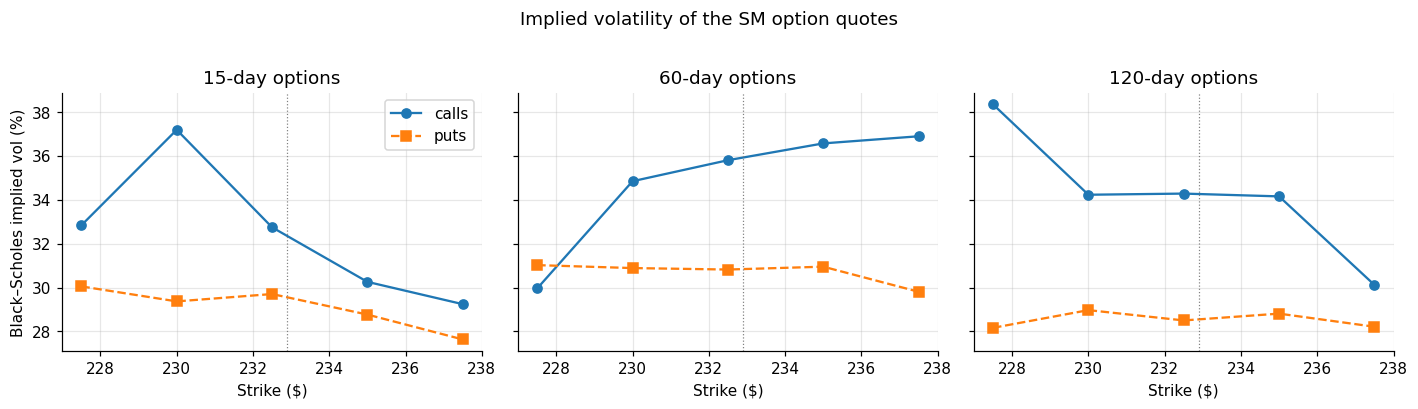

Lowest MSE any parity-consistent model can reach, per maturity:
Days
15    0.2056
60    1.2694
120   3.9111


Type,Days,Strike,C,P,C-P (market),S0-Ke^(-rT) (theory),gap
0,15,227.5000,10.5200,4.3200,6.2000,5.6047,0.5953
1,15,230.0000,10.0500,5.2000,4.8500,3.1069,1.7431
2,15,232.5000,7.7500,6.4500,1.3000,0.6092,0.6908
3,15,235.0000,6.0100,7.5600,-1.5500,-1.8886,0.3386
4,15,237.5000,4.7500,8.7800,-4.0300,-4.3863,0.3563
5,60,227.5000,16.7800,11.0300,5.7500,6.2175,-0.4675
6,60,230.0000,17.6500,12.1500,5.5000,3.7265,1.7735
7,60,232.5000,16.8600,13.3700,3.4900,1.2355,2.2545
8,60,235.0000,16.0500,14.7500,1.3000,-1.2555,2.5555
9,60,237.5000,15.1000,15.6200,-0.5200,-3.7465,3.2265


In [ ]:
def bs_price(S, K, T, r, sig, call=True):
    d1 = (np.log(S / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if call:
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def implied_vol(price, K, T, call):
    try:
        return brentq(lambda s: bs_price(S0, K, T, r, s, call) - price, 1e-4, 5.0)
    except ValueError:
        return np.nan

data['IV'] = [implied_vol(p, k, t, ty == 'C') for p, k, t, ty in zip(data.Price, data.Strike, data['T'], data.Type)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, D in zip(axes, [15, 60, 120]):
    for ty, mk in [('C', 'o-'), ('P', 's--')]:
        sub = data[(data.Days == D) & (data.Type == ty)]
        ax.plot(sub.Strike, sub.IV * 100, mk, label='calls' if ty == 'C' else 'puts')
    ax.axvline(S0, color='grey', lw=0.8, ls=':')
    ax.set_title(f'{D}-day options'); ax.set_xlabel('Strike ($)')
axes[0].set_ylabel('Black–Scholes implied vol (%)'); axes[0].legend()
plt.suptitle('Implied volatility of the SM option quotes', y=1.02)
plt.tight_layout(); plt.savefig('figs/fig0_iv.png', bbox_inches='tight'); plt.show()

# put-call parity check: C - P vs S0 - K e^{-rT}
pcp = data.pivot_table(index=['Days', 'Strike'], columns='Type', values='Price').reset_index()
pcp['C-P (market)'] = pcp['C'] - pcp['P']
pcp['S0-Ke^(-rT) (theory)'] = S0 - pcp.Strike * np.exp(-r * pcp.Days / DAYS)
pcp['gap'] = pcp['C-P (market)'] - pcp['S0-Ke^(-rT) (theory)']

# Any model that respects put-call parity must miss each call/put pair by 'gap' in total.
# The best it can do is split the miss evenly (gap/2 on each), which gives a lower bound for the MSE.
floor = pcp.groupby('Days').apply(lambda g: np.sum(2 * (g.gap / 2) ** 2) / (2 * len(g)))
print('Lowest MSE any parity-consistent model can reach, per maturity:')
print(floor.round(4).to_string())
pcp

### 0.2 Pricing engines
**Characteristic functions.** Heston (1993) in the numerically stable "little Heston trap" form (Albrecher et al. 2007); Bates (1996) multiplies it by the characteristic function of a compensated compound-Poisson process with log-normal jumps (Merton 1976): jump intensity $\lambda$, mean log-jump $\mu$, log-jump volatility $\delta$.

**Lewis (2001).** For a call,
$$C_0 = S_0 - \frac{\sqrt{S_0K}\,e^{-rT}}{\pi}\int_0^\infty \mathrm{Re}\!\left[e^{iuk}\,\varphi\!\left(u-\tfrac{i}{2}\right)\right]\frac{du}{u^2+\tfrac14},\qquad k=\ln(S_0/K).$$
The integral is evaluated with adaptive quadrature (`quad`) for single prices and on a fine fixed grid (vectorised over strikes) inside the calibration loop; both agree to ~1e-5 dollars (checked below).

**Carr–Madan (1999).** FFT of the damped call price ($\alpha=1.5$), $N=4096$, $\eta=0.25$, Simpson weights; prices at the quoted strikes are read off the log-strike grid with a cubic spline.

**Puts.** Put–call parity, $P = C - S_0 + Ke^{-rT}$ (option ii in the brief).

In [ ]:
# ---------- characteristic functions of ln(S_T/S_0) under Q ----------
def heston_cf(u, T, r, kappa, theta, sigma, rho, v0):
    d = np.sqrt((rho * sigma * 1j * u - kappa) ** 2 + sigma ** 2 * (1j * u + u ** 2))
    g = (kappa - rho * sigma * 1j * u - d) / (kappa - rho * sigma * 1j * u + d)
    e = np.exp(-d * T)
    C = r * 1j * u * T + kappa * theta / sigma ** 2 * (
        (kappa - rho * sigma * 1j * u - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    D = (kappa - rho * sigma * 1j * u - d) / sigma ** 2 * (1 - e) / (1 - g * e)
    return np.exp(C + D * v0)

def merton_jump_cf(u, T, lamb, mu, delta):
    omega = -lamb * (np.exp(mu + 0.5 * delta ** 2) - 1)          # drift compensator
    return np.exp((1j * u * omega + lamb * (np.exp(1j * u * mu - 0.5 * u ** 2 * delta ** 2) - 1)) * T)

def bates_cf(u, T, r, kappa, theta, sigma, rho, v0, lamb, mu, delta):
    return heston_cf(u, T, r, kappa, theta, sigma, rho, v0) * merton_jump_cf(u, T, lamb, mu, delta)

# ---------- Lewis (2001) ----------
def lewis_call(S0, K, T, r, cf, params):
    k = np.log(S0 / K)
    f = lambda u: (np.exp(1j * u * k) * cf(u - 0.5j, T, r, *params)).real / (u ** 2 + 0.25)
    I = quad(f, 0, 1000, limit=2000)[0]
    return max(0.0, S0 - np.sqrt(S0 * K) * np.exp(-r * T) / np.pi * I)

# integration grid: fine near zero, coarser in the tail; accurate to ~1e-5 $ for vols down to 7% (see checks below)
_U = np.concatenate([np.linspace(1e-8, 60, 6001), np.linspace(60.2, 1000, 4700)])
def lewis_call_vec(S0, K, T, r, cf, params):
    K = np.atleast_1d(K).astype(float)
    k = np.log(S0 / K)[:, None]
    phi = cf(_U - 0.5j, T, r, *params)[None, :]
    integrand = (np.exp(1j * _U[None, :] * k) * phi).real / (_U ** 2 + 0.25)
    I = np.trapezoid(integrand, _U, axis=1)
    return np.maximum(0.0, S0 - np.sqrt(S0 * K) * np.exp(-r * T) / np.pi * I)

# ---------- Carr-Madan (1999) ----------
def carr_madan_call(S0, K, T, r, cf, params, alpha=1.5, N=4096, eta=0.25):
    lam = 2 * np.pi / (N * eta)                     # log-strike spacing
    b = 0.5 * N * lam
    v = eta * np.arange(N)
    ku = -b + lam * np.arange(N)
    psi = np.exp(-r * T) * cf(v - (alpha + 1) * 1j, T, r, *params) / (
        alpha ** 2 + alpha - v ** 2 + 1j * (2 * alpha + 1) * v)
    w = (3 + (-1) ** np.arange(1, N + 1)) / 3.0; w[0] -= 1 / 3.0     # Simpson weights
    calls = np.exp(-alpha * ku) / np.pi * np.fft.fft(np.exp(1j * b * v) * psi * eta * w).real
    m = (ku > -1) & (ku < 1)
    return np.maximum(S0 * CubicSpline(ku[m], calls[m])(np.log(np.atleast_1d(K) / S0)), 0.0)

def put_from_call(C, S0, K, T, r):
    return C - S0 + K * np.exp(-r * T)

**Sanity checks.** (i) With almost no vol-of-vol and $v_0=\theta$, Heston must collapse to Black–Scholes. (ii) Lewis (quad), Lewis (grid) and Carr–Madan must agree for an arbitrary Bates parameter set.

In [ ]:
Ks = np.array([227.5, 230, 232.5, 235, 237.5])
T = 15 / DAYS
chk = pd.DataFrame({'Strike': Ks,
    'Black-Scholes (30%)': [bs_price(S0, k, T, r, 0.3) for k in Ks],
    'Heston->BS Lewis': [lewis_call(S0, k, T, r, heston_cf, (2, 0.09, 1e-4, 0, 0.09)) for k in Ks],
    'Heston->BS Carr-Madan': carr_madan_call(S0, Ks, T, r, heston_cf, (2, 0.09, 1e-4, 0, 0.09))})
pb = (3, 0.1, 0.6, -0.6, 0.12, 0.5, -0.1, 0.15)
chk['Bates Lewis quad'] = [lewis_call(S0, k, T, r, bates_cf, pb) for k in Ks]
chk['Bates Lewis grid'] = lewis_call_vec(S0, Ks, T, r, bates_cf, pb)
chk['Bates Carr-Madan'] = carr_madan_call(S0, Ks, T, r, bates_cf, pb)
chk

,Strike,Black-Scholes (30%),Heston->BS Lewis,Heston->BS Carr-Madan,Bates Lewis quad,Bates Lewis grid,Bates Carr-Madan
0,227.5000,9.9134,9.9134,9.9134,11.2493,11.2493,11.2493
1,230.0000,8.4470,8.4470,8.4470,9.7540,9.7540,9.7540
2,232.5000,7.1262,7.1262,7.1262,8.3804,8.3804,8.3804
3,235.0000,5.9509,5.9509,5.9509,7.1315,7.1315,7.1315
4,237.5000,4.9181,4.9181,4.9181,6.0081,6.0081,6.0081


### 0.3 Calibration machinery
* **Error function:** plain mean squared error over the calibration set,
$\displaystyle \text{MSE}(p)=\frac1N\sum_{n=1}^N\big(C^{\text{model}}_n(p)-C^{\text{market}}_n\big)^2$, calls and puts pooled.
* **Constraints (penalty of 500 if violated):** $\kappa>0$, $\theta\ge0.005$, $\sigma>0$, $-1\le\rho\le1$, $v_0\ge0.005$ (i.e. spot and long-run vol of at least ~7%, which keeps the Fourier integrals well behaved) and the Feller condition $2\kappa\theta\ge\sigma^2$ (keeps the variance strictly positive). For jumps: $\lambda\ge0$, $\delta\ge0$, $-0.6\le\mu\le0.6$, $\lambda\le 5$.
* **Optimiser:** a coarse global grid search (`brute`) to find a good starting region, then a local Nelder–Mead simplex (`fmin`) — the standard two-stage approach of Hilpisch (2015).

In [ ]:
HESTON_GRID = ((2.5, 10.6, 4.0),      # kappa
               (0.02, 0.21, 0.06),    # theta
               (0.1, 0.91, 0.2),      # sigma
               (-0.75, 0.26, 0.25),   # rho
               (0.02, 0.21, 0.06))    # v0
H_NAMES = ['kappa', 'theta', 'sigma', 'rho', 'v0']
J_NAMES = ['lambda', 'mu', 'delta']

def model_prices(df, cf, params, method):
    # model prices (calls directly, puts via put-call parity) for every row of df
    out = np.empty(len(df))
    for T_, idx in df.groupby('T').groups.items():
        sub = df.loc[idx]
        K = sub.Strike.values
        C = lewis_call_vec(S0, K, T_, r, cf, params) if method == 'lewis' else carr_madan_call(S0, K, T_, r, cf, params)
        P = put_from_call(C, S0, K, T_, r)
        out[df.index.get_indexer(idx)] = np.where(sub.Type.values == 'C', C, P)
    return out

def heston_ok(p):
    kappa, theta, sigma, rho, v0 = p
    return (kappa > 0) and (theta >= 0.005) and (sigma > 0) and (-1 <= rho <= 1) and (v0 >= 0.005) \
        and (2 * kappa * theta >= sigma ** 2)

def jumps_ok(j):
    lamb, mu, delta = j
    return (0 <= lamb <= 5) and (-0.6 <= mu <= 0.6) and (delta >= 0)

def mse_heston(p, df, method):
    if not heston_ok(p): return 500.0
    return np.mean((model_prices(df, heston_cf, p, method) - df.Price.values) ** 2)

def calibrate_heston(df, method):
    t0 = time.time()
    p0 = brute(mse_heston, HESTON_GRID, args=(df, method), finish=None)
    p = fmin(mse_heston, p0, args=(df, method), xtol=1e-7, ftol=1e-7, maxiter=3000, maxfun=5000, disp=False)
    return p, mse_heston(p, df, method), time.time() - t0

def fit_table(df, cf, params, method):
    out = df[['Days', 'Strike', 'Type', 'Price']].copy()
    out['Model'] = model_prices(df, cf, params, method)
    out['Error'] = out.Model - out.Price
    return out

def plot_fit(tab, title, fname):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    for ax, ty, name in [(axes[0], 'C', 'Calls'), (axes[1], 'P', 'Puts')]:
        s = tab[tab.Type == ty]
        ax.plot(s.Strike, s.Price, 'o', ms=8, label='market')
        ax.plot(s.Strike, s.Model, 'x-', ms=8, label='model')
        ax.axvline(S0, color='grey', ls=':', lw=0.8)
        ax.set_title(name); ax.set_xlabel('Strike ($)'); ax.set_ylabel('Option price ($)'); ax.legend()
    w = 0.9
    c = tab[tab.Type == 'C']; p = tab[tab.Type == 'P']
    axes[2].bar(c.Strike - w / 2, c.Error, width=w, label='calls')
    axes[2].bar(p.Strike + w / 2, p.Error, width=w, label='puts')
    axes[2].axhline(0, color='k', lw=0.7)
    axes[2].set_title('Pricing error (model − market)'); axes[2].set_xlabel('Strike ($)'); axes[2].set_ylabel('$'); axes[2].legend()
    plt.suptitle(title, y=1.03); plt.tight_layout(); plt.savefig(fname, bbox_inches='tight'); plt.show()

---
## Step 1a — Heston (1993) calibrated with Lewis (2001) [Member A]
Target: the 15-day options only (5 calls + 5 puts, $T=15/250=0.06$), since the client's product is short-dated. Calls priced with the Lewis formula, puts via put–call parity, MSE error, Feller constraint imposed.

In [ ]:
d15 = data[data.Days == 15].reset_index(drop=True)
p_h_lewis, mse_h_lewis, sec = calibrate_heston(d15, 'lewis')
print(f'Calibration time: {sec:.1f}s')
res_h = pd.DataFrame({'Lewis (2001)': p_h_lewis}, index=H_NAMES)
print(res_h.T.to_string())
print(f'MSE = {mse_h_lewis:.5f}   RMSE = ${np.sqrt(mse_h_lewis):.4f}')
print(f'Feller: 2*kappa*theta = {2*p_h_lewis[0]*p_h_lewis[1]:.4f}  vs  sigma^2 = {p_h_lewis[2]**2:.4f}')

Calibration time: 10.4s
              kappa  theta  sigma     rho     v0
Lewis (2001) 6.2904 0.1236 1.2470 -1.0000 0.0959
MSE = 0.24658   RMSE = $0.4966
Feller: 2*kappa*theta = 1.5551  vs  sigma^2 = 1.5551


In [ ]:
tab_h_lewis = fit_table(d15, heston_cf, p_h_lewis, 'lewis')
plot_fit(tab_h_lewis, 'Step 1a — Heston (1993) via Lewis (2001), 15-day SM options', 'figs/fig1a_heston_lewis.png')
tab_h_lewis

**Robustness check.** The same calibration without the Feller penalty, to see how much the constraint costs in fit and whether the parameters are well identified with a single, very short maturity.

In [ ]:
def mse_heston_nofeller(p, df, method):
    kappa, theta, sigma, rho, v0 = p
    if kappa < 0 or theta < 0.005 or sigma < 0 or not (-1 <= rho <= 1) or v0 < 0.005: return 500.0
    return np.mean((model_prices(df, heston_cf, p, method) - df.Price.values) ** 2)

p0 = brute(mse_heston_nofeller, HESTON_GRID, args=(d15, 'lewis'), finish=None)
p_nf = fmin(mse_heston_nofeller, p0, args=(d15, 'lewis'), xtol=1e-7, ftol=1e-7, maxiter=3000, maxfun=5000, disp=False)
pd.DataFrame({'with Feller': list(p_h_lewis) + [mse_h_lewis],
              'without Feller': list(p_nf) + [mse_heston_nofeller(p_nf, d15, 'lewis')]},
             index=H_NAMES + ['MSE'])

## Step 1b — Heston (1993) calibrated with Carr–Madan (1999) [Member B]
Identical set-up (15-day calls and puts, MSE, same constraints, same brute grid + Nelder–Mead); only the pricing engine changes to the FFT.

In [ ]:
p_h_cm, mse_h_cm, sec = calibrate_heston(d15, 'cm')
print(f'Calibration time: {sec:.1f}s')
res_h['Carr-Madan (1999)'] = p_h_cm
res_h.loc['MSE'] = [mse_h_lewis, mse_h_cm]
res_h.loc['RMSE ($)'] = np.sqrt(res_h.loc['MSE'])
res_h['difference'] = res_h['Carr-Madan (1999)'] - res_h['Lewis (2001)']
res_h

In [ ]:
tab_h_cm = fit_table(d15, heston_cf, p_h_cm, 'cm')
plot_fit(tab_h_cm, 'Step 1b — Heston (1993) via Carr–Madan (1999), 15-day SM options', 'figs/fig1b_heston_cm.png')
# cross-check: price with the *other* method using each parameter set
xc = pd.DataFrame({'Strike': d15.Strike, 'Type': d15.Type,
                   'Lewis params, Lewis price': model_prices(d15, heston_cf, p_h_lewis, 'lewis'),
                   'Lewis params, CM price': model_prices(d15, heston_cf, p_h_lewis, 'cm'),
                   'CM params, CM price': model_prices(d15, heston_cf, p_h_cm, 'cm')})
xc

## Step 1c — 20-day ATM Asian call by Monte Carlo [Member C]
* Parameters: Heston set from Step 1a (Lewis). Lewis and Carr–Madan give practically the same set, so the choice does not matter; Lewis is used because the integral is evaluated directly at each strike with no interpolation.
* Strike $K=S_0=232.90$ (ATM), $T=20/250$.
* Payoff $\max(\bar S-K,0)$ with $\bar S=\frac1{21}\sum_{t=0}^{20}S_t$ (today's price plus 20 daily closes).
* Dynamics simulated under $Q$: log-Euler for the price and full-truncation Euler for the variance (Lord, Koekkoek and van Dijk 2010), correlated normals, **10 sub-steps per trading day** (200 steps), antithetic variates.
* Convergence is checked by repeating the experiment with increasing numbers of paths; the simulator is also validated on the European call with the same maturity, where the exact (Lewis) price is known.

In [ ]:
def simulate_heston_daily(params, S0, r, n_days, n_paths, substeps=10, seed=42, jumps=None):
    # returns array (n_days+1, n_paths) of daily prices (antithetic: n_paths must be even)
    kappa, theta, sigma, rho, v0 = params
    rng = np.random.default_rng(seed)
    dt = 1 / DAYS / substeps
    half = n_paths // 2
    lnS = np.full(n_paths, np.log(S0)); v = np.full(n_paths, v0)
    out = np.empty((n_days + 1, n_paths)); out[0] = S0
    if jumps is not None:
        lamb, mu, delta = jumps
        comp = lamb * (np.exp(mu + 0.5 * delta ** 2) - 1)
    for day in range(1, n_days + 1):
        for _ in range(substeps):
            z1 = rng.standard_normal(half); z2 = rng.standard_normal(half)
            z1 = np.concatenate([z1, -z1]); z2 = np.concatenate([z2, -z2])
            zv = rho * z1 + np.sqrt(1 - rho ** 2) * z2
            vp = np.maximum(v, 0)
            drift = (r - 0.5 * vp) * dt
            if jumps is not None:
                nj = rng.poisson(lamb * dt, n_paths)
                J = nj * mu + np.sqrt(nj) * delta * rng.standard_normal(n_paths)
                lnS += drift - comp * dt + np.sqrt(vp * dt) * z1 + J
            else:
                lnS += drift + np.sqrt(vp * dt) * z1
            v = v + kappa * (theta - vp) * dt + sigma * np.sqrt(vp * dt) * zv
        out[day] = np.exp(lnS)
    return out

T_A, K_A, N_A = 20 / DAYS, S0, 20
paths = simulate_heston_daily(p_h_lewis, S0, r, N_A, 200_000, seed=7)
disc = np.exp(-r * T_A)
asian_pay = np.maximum(paths.mean(axis=0) - K_A, 0)
euro_pay = np.maximum(paths[-1] - K_A, 0)

asian_mc = disc * asian_pay.mean()
asian_se = disc * asian_pay.reshape(2, -1).mean(axis=0).std(ddof=1) / np.sqrt(asian_pay.size // 2)  # antithetic pairs
euro_mc = disc * euro_pay.mean()
euro_exact = lewis_call(S0, K_A, T_A, r, heston_cf, p_h_lewis)
print(f'European 20-day ATM call: MC = {euro_mc:.4f}   Lewis exact = {euro_exact:.4f}   diff = {euro_mc-euro_exact:+.4f}')
print(f'Asian 20-day ATM call   : MC = {asian_mc:.4f}   (std. error {asian_se:.4f}, 95% CI {asian_mc-1.96*asian_se:.4f} – {asian_mc+1.96*asian_se:.4f})')

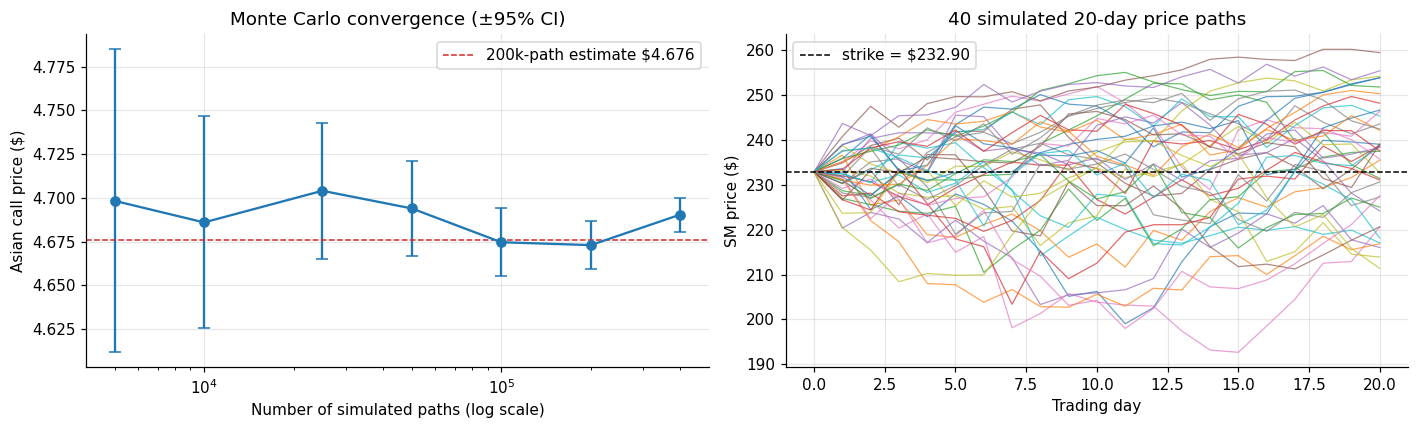

,paths,price,std_error
0,5000,4.6983,0.0442
1,10000,4.6859,0.0310
2,25000,4.7040,0.0198
3,50000,4.6939,0.0139
4,100000,4.6746,0.0099
5,200000,4.6729,0.0070
6,400000,4.6904,0.0049


In [ ]:
# convergence study: independent runs with growing path counts
conv = []
for n in [5_000, 10_000, 25_000, 50_000, 100_000, 200_000, 400_000]:
    pth = simulate_heston_daily(p_h_lewis, S0, r, N_A, n, seed=1000 + n // 1000)
    pay = np.maximum(pth.mean(axis=0) - K_A, 0)
    pairs = pay.reshape(2, -1).mean(axis=0)
    conv.append((n, disc * pay.mean(), disc * pairs.std(ddof=1) / np.sqrt(pairs.size)))
conv = pd.DataFrame(conv, columns=['paths', 'price', 'std_error'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(conv.paths, conv.price, yerr=1.96 * conv.std_error, fmt='o-', capsize=4)
axes[0].axhline(asian_mc, color='C3', ls='--', lw=1, label=f'200k-path estimate ${asian_mc:.3f}')
axes[0].set_xscale('log'); axes[0].set_xlabel('Number of simulated paths (log scale)'); axes[0].set_ylabel('Asian call price ($)')
axes[0].set_title('Monte Carlo convergence (±95% CI)'); axes[0].legend()
for i in range(40):
    axes[1].plot(np.arange(N_A + 1), paths[:, i], lw=0.8, alpha=0.7)
axes[1].axhline(K_A, color='k', ls='--', lw=1, label='strike = $232.90')
axes[1].set_xlabel('Trading day'); axes[1].set_ylabel('SM price ($)'); axes[1].set_title('40 simulated 20-day price paths'); axes[1].legend()
plt.tight_layout(); plt.savefig('figs/fig1c_asian.png', bbox_inches='tight'); plt.show()
conv

In [ ]:
FEE = 0.04
asian_client = asian_mc * (1 + FEE)
pd.DataFrame({'value ($)': [asian_mc, asian_mc * FEE, asian_client, euro_exact]},
             index=['Fair value (MC, risk-neutral)', 'Bank fee (4%)', 'Price charged to client',
                    'memo: European ATM call, same maturity'])

,value ($)
"Fair value (MC, risk-neutral)",4.6758
Bank fee (4%),0.1870
Price charged to client,4.8628
"memo: European ATM call, same maturity",8.1797


---
## Step 2a — Bates (1996) calibrated with Lewis (2001), 60-day options [Member C]
Calibration set: the 60-day calls and puts ($T=60/250=0.24$). Same error function, rate, day count and put–call parity as Step 1a. Following Hilpisch (2015), the 8-parameter calibration is done in three stages, because a direct search over 8 dimensions is slow and easily lands in a poor local minimum:

1. **Stochastic-volatility part:** calibrate a pure Heston model to the 60-day options (brute grid + Nelder–Mead).
2. **Jump part:** hold the five Heston parameters fixed and calibrate $(\lambda,\mu,\delta)$ only (brute grid + Nelder–Mead).
3. **Full calibration:** starting from stages 1–2, run Nelder–Mead on all eight parameters jointly, with the same constraints.
4. **Global check:** because an 8-parameter surface is easily multi-modal, the full Nelder–Mead is also restarted from 12 random admissible points. The parameter set with the lowest MSE across stage 3 and the restarts is kept.

In [ ]:
JUMP_GRID = ((0.0, 3.01, 0.5),       # lambda
             (-0.4, 0.41, 0.1),      # mu (both negative and positive jumps allowed)
             (0.0, 0.31, 0.1))       # delta

def mse_jumps(j, hp, df, method):
    if not jumps_ok(j): return 500.0
    return np.mean((model_prices(df, bates_cf, tuple(hp) + tuple(j), method) - df.Price.values) ** 2)

def mse_bates(p, df, method):
    if not (heston_ok(p[:5]) and jumps_ok(p[5:])): return 500.0
    return np.mean((model_prices(df, bates_cf, p, method) - df.Price.values) ** 2)

def random_bates_starts(n, seed=123):
    rng = np.random.default_rng(seed); out = []
    while len(out) < n:
        x0 = np.array([rng.uniform(0.5, 8), rng.uniform(0.02, 0.2), rng.uniform(0.05, 0.6), rng.uniform(-0.9, 0.9),
                       rng.uniform(0.02, 0.2), rng.uniform(0, 3), rng.uniform(-0.4, 0.4), rng.uniform(0, 0.4)])
        if heston_ok(x0[:5]) and jumps_ok(x0[5:]): out.append(x0)
    return out

def calibrate_bates(df, method, n_restarts=12):
    t0 = time.time()
    hp, h_mse, _ = calibrate_heston(df, method)                                    # stage 1
    j0 = brute(mse_jumps, JUMP_GRID, args=(hp, df, method), finish=None)            # stage 2
    j = fmin(mse_jumps, j0, args=(hp, df, method), xtol=1e-7, ftol=1e-7, maxiter=2000, maxfun=3000, disp=False)
    j_mse = mse_jumps(j, hp, df, method)
    p3 = fmin(mse_bates, np.r_[hp, j], args=(df, method), xtol=1e-7, ftol=1e-7,    # stage 3
              maxiter=8000, maxfun=12000, disp=False)
    # stage 4: global check - full Nelder-Mead from random starting points
    ms = []
    for x0 in random_bates_starts(n_restarts):
        x = fmin(mse_bates, x0, args=(df, method), xtol=1e-7, ftol=1e-7, maxiter=6000, maxfun=8000, disp=False)
        ms.append(list(x) + [mse_bates(x, df, method)])
    ms = pd.DataFrame(ms, columns=H_NAMES + J_NAMES + ['MSE']).sort_values('MSE').reset_index(drop=True)
    p4 = ms.iloc[0, :8].values
    p = p4 if ms.MSE.iloc[0] < mse_bates(p3, df, method) else p3
    stages = pd.DataFrame({'1: Heston only': list(hp) + [np.nan] * 3 + [h_mse],
                           '2: + jumps (SV fixed)': list(hp) + list(j) + [j_mse],
                           '3: full Bates from 1-2': list(p3) + [mse_bates(p3, df, method)],
                           '4: best of restarts': list(p4) + [ms.MSE.iloc[0]]},
                          index=H_NAMES + J_NAMES + ['MSE'])
    return p, stages, ms, time.time() - t0

d60 = data[data.Days == 60].reset_index(drop=True)
p_b_lewis, stages_lewis, ms_lewis, sec = calibrate_bates(d60, 'lewis')
print(f'Calibration time: {sec:.1f}s')
stages_lewis

Calibration time: 264.4s


,1: Heston only,2: + jumps (SV fixed),3: full Bates from 1-2,4: best of restarts
kappa,5.1261,5.1261,5.1089,8.5123
theta,0.1075,0.1075,0.1078,0.0050
sigma,1.0498,1.0498,1.0496,0.1148
rho,0.9958,0.9958,1.0000,0.4265
v0,0.1217,0.1217,0.1216,0.0050
lambda,NaN,0.0081,0.0000,1.8636
mu,NaN,-0.0407,-0.0494,0.2143
delta,NaN,0.0000,0.0000,0.0002
MSE,1.3628,1.3628,1.3626,1.3375


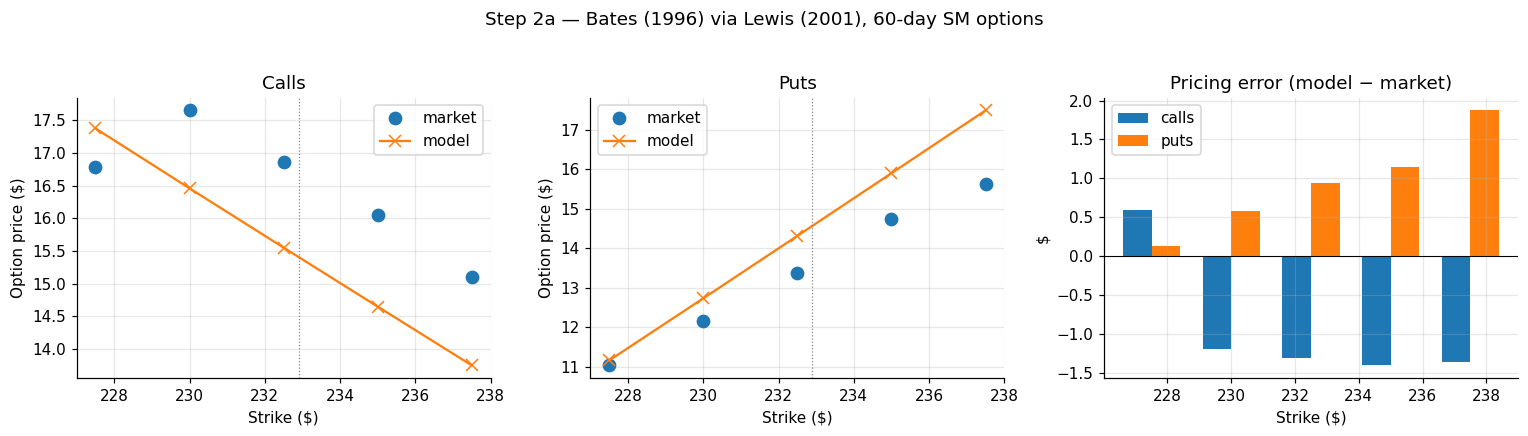

Feller: 2*kappa*theta = 0.0851 vs sigma^2 = 0.0132
Expected jump size E[e^J - 1] = +23.8948%,  jumps per year = 1.864


,Days,Strike,Type,Price,Model,Error
0,60,227.5000,C,16.7800,17.3742,0.5942
1,60,230.0000,C,17.6500,16.4570,-1.1930
2,60,232.5000,C,16.8600,15.5489,-1.3111
3,60,235.0000,C,16.0500,14.6459,-1.4041
4,60,237.5000,C,15.1000,13.7461,-1.3539
5,60,227.5000,P,11.0300,11.1567,0.1267
6,60,230.0000,P,12.1500,12.7305,0.5805
7,60,232.5000,P,13.3700,14.3135,0.9435
8,60,235.0000,P,14.7500,15.9015,1.1515
9,60,237.5000,P,15.6200,17.4926,1.8726


In [ ]:
tab_b_lewis = fit_table(d60, bates_cf, p_b_lewis, 'lewis')
plot_fit(tab_b_lewis, 'Step 2a — Bates (1996) via Lewis (2001), 60-day SM options', 'figs/fig2a_bates_lewis.png')
kappa, theta, sigma, rho, v0, lamb, mu, delta = p_b_lewis
print(f'Feller: 2*kappa*theta = {2*kappa*theta:.4f} vs sigma^2 = {sigma**2:.4f}')
print(f'Expected jump size E[e^J - 1] = {np.exp(mu + 0.5*delta**2) - 1:+.4%},  jumps per year = {lamb:.3f}')
tab_b_lewis

## Step 2b — Bates (1996) calibrated with Carr–Madan (1999), 60-day options [Member A]
Same three-stage procedure and constraints; the FFT replaces the Lewis integral.

In [ ]:
p_b_cm, stages_cm, ms_cm, sec = calibrate_bates(d60, 'cm')
print(f'Calibration time: {sec:.1f}s')
stages_cm

Calibration time: 118.5s


,1: Heston only,2: + jumps (SV fixed),3: full Bates from 1-2,4: best of restarts
kappa,4.9852,4.9852,4.9852,8.5307
theta,0.0954,0.0954,0.0954,0.0050
sigma,0.9752,0.9752,0.9752,0.1179
rho,1.0000,1.0000,1.0000,0.4016
v0,0.1284,0.1284,0.1284,0.0060
lambda,NaN,0.0000,0.0000,1.8586
mu,NaN,-0.4039,-0.4121,0.2145
delta,NaN,0.0001,0.0001,0.0011
MSE,1.3641,1.3641,1.3641,1.3380


In [ ]:
tab_b_cm = fit_table(d60, bates_cf, p_b_cm, 'cm')
plot_fit(tab_b_cm, 'Step 2b — Bates (1996) via Carr–Madan (1999), 60-day SM options', 'figs/fig2b_bates_cm.png')
res_b = pd.DataFrame({'Lewis (2001)': list(p_b_lewis) + [mse_bates(p_b_lewis, d60, 'lewis')],
                      'Carr-Madan (1999)': list(p_b_cm) + [mse_bates(p_b_cm, d60, 'cm')]},
                     index=H_NAMES + J_NAMES + ['MSE'])
res_b.loc['RMSE ($)'] = np.sqrt(res_b.loc['MSE'])
res_b['difference'] = res_b.iloc[:, 1] - res_b.iloc[:, 0]
res_b

**How well identified are the Bates parameters?** The 12 restarts of stage 4 (Lewis engine) show how flat the error surface is: very different parameter combinations reach almost the same MSE, all of them above the floor set by the put–call parity violations in the quotes (section 0.1).

In [ ]:
print(f"MSE across restarts: {ms_lewis.MSE.min():.4f} – {ms_lewis.MSE.max():.4f}   (parity floor for 60-day quotes: {floor.loc[60]:.4f})")
ms_lewis

## Step 2c — 70-day European put, strike 95% of spot [Member B]
* $K = 0.95\times232.90 = 221.255$, $T=70/250=0.28$.
* Parameters: Bates set from Step 2a (Lewis). Note the 70-day maturity is 10 trading days beyond the 60-day options used in calibration, so this is a mild extrapolation.
* Because the product is a plain European put, the model has a semi-closed-form price (Lewis call + put–call parity). We report that as the fair value and confirm it with a Monte Carlo simulation of the Bates dynamics (same discretisation as Step 1c plus log-normal jumps), mirroring the process of Step 1c.
* A 4% fee is added on top of the fair value.

In [ ]:
K_P, T_P, N_P = 0.95 * S0, 70 / DAYS, 70
call_P = lewis_call(S0, K_P, T_P, r, bates_cf, p_b_lewis)
put_fair = put_from_call(call_P, S0, K_P, T_P, r)
put_cm = put_from_call(carr_madan_call(S0, K_P, T_P, r, bates_cf, p_b_lewis)[0], S0, K_P, T_P, r)

pth = simulate_heston_daily(p_b_lewis[:5], S0, r, N_P, 200_000, seed=11, jumps=p_b_lewis[5:])
pay = np.maximum(K_P - pth[-1], 0)
pairs = pay.reshape(2, -1).mean(axis=0)
put_mc = np.exp(-r * T_P) * pay.mean(); put_se = np.exp(-r * T_P) * pairs.std(ddof=1) / np.sqrt(pairs.size)

# Black-Scholes reference at the 60-day 95%-ish put implied vol and Heston-only reference
iv_ref = data[(data.Days == 60) & (data.Type == 'P')].IV.mean()
put_bs = bs_price(S0, K_P, T_P, r, iv_ref, call=False)

print(f'Strike = {K_P:.3f}, T = {T_P:.3f} years')
print(f'Bates fair value (Lewis)       : {put_fair:.4f}')
print(f'Bates fair value (Carr-Madan)  : {put_cm:.4f}')
print(f'Bates Monte Carlo (200k paths) : {put_mc:.4f} ± {1.96*put_se:.4f} (95% CI)')
print(f'memo: Black-Scholes at avg 60-day put IV {iv_ref:.2%}: {put_bs:.4f}')
# robustness: the same put priced with every near-optimal parameter set from the restarts
ms_lewis['put_70d_95'] = [put_from_call(lewis_call_vec(S0, K_P, T_P, r, bates_cf, row[:8])[0], S0, K_P, T_P, r) for row in ms_lewis.values]
good = ms_lewis[ms_lewis.MSE <= ms_lewis.MSE.min() * 1.02]
print(f'Put price across the {len(good)} restarts within 2% of the best MSE: {good.put_70d_95.min():.4f} – {good.put_70d_95.max():.4f}')
p3 = stages_lewis['3: full Bates from 1-2'].values[:8]
put_stage3 = put_from_call(lewis_call(S0, K_P, T_P, r, bates_cf, p3), S0, K_P, T_P, r)
print(f'Put price with the stage-3 (almost jump-free) parameter set: {put_stage3:.4f}')
display(ms_lewis[['lambda', 'mu', 'delta', 'v0', 'MSE', 'put_70d_95']])
put_tab = pd.DataFrame({'value ($)': [put_fair, put_fair * FEE, put_fair * (1 + FEE)]},
                       index=['Fair value', 'Bank fee (4%)', 'Price charged to client'])
put_tab

Strike = 221.255, T = 0.280 years
Bates fair value (Lewis)       : 8.8364
Bates fair value (Carr-Madan)  : 8.8364
Bates Monte Carlo (200k paths) : 8.8403 ± 0.0360 (95% CI)
memo: Black-Scholes at avg 60-day put IV 30.70%: 9.2292
Put price across the 3 restarts within 2% of the best MSE: 8.8364 – 9.0237
Put price with the stage-3 (almost jump-free) parameter set: 8.8159


,lambda,mu,delta,v0,MSE,put_70d_95
0,1.8636,0.2143,0.0002,0.0050,1.3375,8.8364
1,2.5873,0.1639,0.0954,0.0050,1.3500,8.8951
2,2.6453,0.1582,0.0952,0.0059,1.3518,9.0237
3,0.9303,0.2414,0.1775,0.0112,1.3713,9.5548
4,0.0603,-0.0987,1.5446,0.0496,1.3753,9.4284
5,0.0990,0.5999,0.7815,1.4903,1.3814,8.8444
6,2.2642,0.1617,0.0824,0.0602,1.3822,9.3749
7,0.2402,-0.0007,0.9429,0.0433,1.3864,9.5515
8,0.4070,-0.0138,0.7239,0.0622,1.3866,9.4396
9,0.4248,0.3583,0.0000,0.0268,1.4007,10.0059


,value ($)
Fair value,8.8364
Bank fee (4%),0.3535
Price charged to client,9.1899


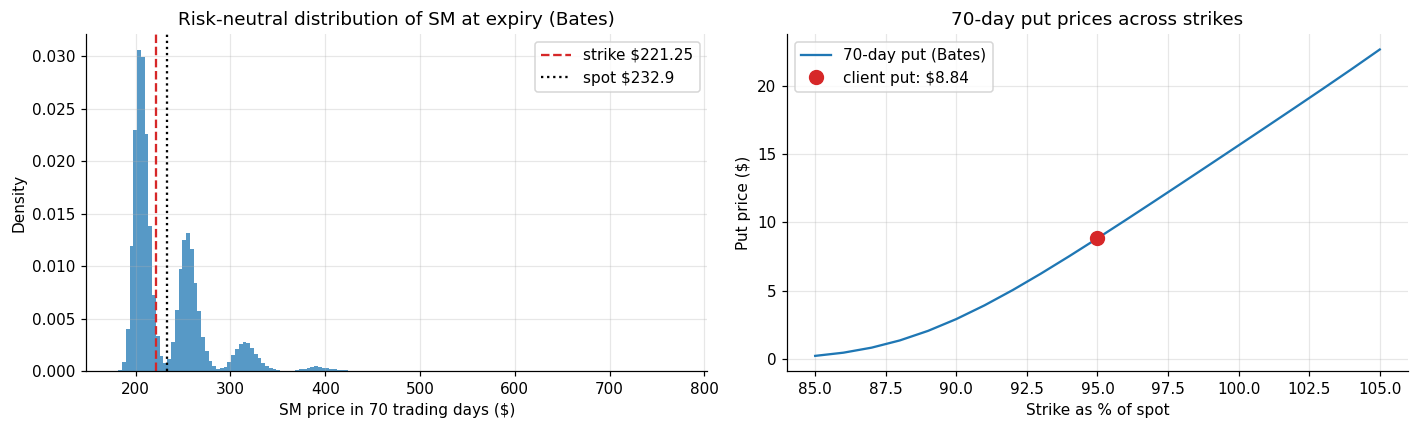

Risk-neutral probability the put finishes in the money: 57.21%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ST = pth[-1]
axes[0].hist(ST, bins=150, density=True, alpha=0.75)
axes[0].axvline(K_P, color='C3', ls='--', label=f'strike ${K_P:.2f}'); axes[0].axvline(S0, color='k', ls=':', label=f'spot ${S0}')
axes[0].set_xlabel('SM price in 70 trading days ($)'); axes[0].set_ylabel('Density'); axes[0].set_title('Risk-neutral distribution of SM at expiry (Bates)')
axes[0].legend()
strikes = np.linspace(0.85, 1.05, 21) * S0
puts = put_from_call(np.array([lewis_call(S0, k, T_P, r, bates_cf, p_b_lewis) for k in strikes]), S0, strikes, T_P, r)
axes[1].plot(strikes / S0 * 100, puts, '-', label='70-day put (Bates)')
axes[1].plot(95, put_fair, 'o', color='C3', ms=9, label=f'client put: ${put_fair:.2f}')
axes[1].set_xlabel('Strike as % of spot'); axes[1].set_ylabel('Put price ($)'); axes[1].set_title('70-day put prices across strikes'); axes[1].legend()
plt.tight_layout(); plt.savefig('figs/fig2c_put.png', bbox_inches='tight'); plt.show()
print(f'Risk-neutral probability the put finishes in the money: {(ST < K_P).mean():.2%}')

---
## Step 3a — Euribor term structure and CIR (1985) calibration [Team]
**Market data (from the brief):** Euribor 1w 0.648%, 1m 0.679%, 3m 1.173%, 6m 1.809%, 12m 2.556%.

**Process**
1. *Build the term structure.* Euribor is a simple, ACT/360 money-market rate. Each quote is converted to a continuously compounded zero rate, $y(T)=\ln(1+L\,\tau)/T$ with $\tau = 365T/360$, so that it is consistent with the CIR bond-pricing formula.
2. *Interpolate.* A natural cubic spline through the five zero rates gives weekly zero rates for $t=1/52,\dots,52/52$ (52 points), and from its derivative the instantaneous forward rates $f(0,t)=y(t)+t\,y'(t)$.
3. *Calibrate CIR.* Under CIR, $dr_t=\kappa_r(\theta_r-r_t)dt+\sigma_r\sqrt{r_t}\,dW_t$, the model forward curve is
$$f^{CIR}(0,t)=\frac{2\kappa_r\theta_r\,(e^{\gamma t}-1)}{2\gamma+(\kappa_r+\gamma)(e^{\gamma t}-1)}+r_0\,\frac{4\gamma^2e^{\gamma t}}{\big(2\gamma+(\kappa_r+\gamma)(e^{\gamma t}-1)\big)^2},\qquad \gamma=\sqrt{\kappa_r^2+2\sigma_r^2}.$$
$r_0$ is fixed at the 1-week rate (the shortest observable rate) and $(\kappa_r,\theta_r,\sigma_r)$ minimise the MSE between model and spline forward rates, subject to positivity and the Feller condition $2\kappa_r\theta_r\ge\sigma_r^2$ (Hilpisch 2015).
4. *Check the fit* in terms of zero rates and Euribor quotes using the CIR zero-coupon bond price $B(0,T)$.

In [ ]:
eur_T = np.array([1 / 52, 1 / 12, 3 / 12, 6 / 12, 1.0])
eur_L = np.array([0.648, 0.679, 1.173, 1.809, 2.556]) / 100
tau = eur_T * 365 / 360
eur_y = np.log(1 + eur_L * tau) / eur_T                     # continuously compounded zero rates

spline = CubicSpline(eur_T, eur_y, bc_type='natural')
t_w = np.arange(1, 53) / 52
y_w = spline(t_w)
f_w = y_w + t_w * spline(t_w, 1)                            # instantaneous forwards
r0_cir = eur_y[0]

pd.DataFrame({'maturity (yrs)': eur_T, 'Euribor (simple, %)': eur_L * 100, 'zero rate (cont., %)': eur_y * 100})

,maturity (yrs),"Euribor (simple, %)","zero rate (cont., %)"
0,0.0192,0.6480,0.6570
1,0.0833,0.6790,0.6882
2,0.2500,1.1730,1.1875
3,0.5000,1.8090,1.8258
4,1.0000,2.5560,2.5585


In [ ]:
def cir_forward(t, r0, kappa, theta, sigma):
    g = np.sqrt(kappa ** 2 + 2 * sigma ** 2)
    e = np.exp(g * t) - 1
    den = 2 * g + (kappa + g) * e
    return 2 * kappa * theta * e / den + r0 * 4 * g ** 2 * np.exp(g * t) / den ** 2

def cir_zcb(r_, T, kappa, theta, sigma):
    # zero-coupon bond price B(t, t+T) given short rate r_
    g = np.sqrt(kappa ** 2 + 2 * sigma ** 2)
    e = np.exp(g * T) - 1
    den = 2 * g + (kappa + g) * e
    A = (2 * g * np.exp((kappa + g) * T / 2) / den) ** (2 * kappa * theta / sigma ** 2)
    Bc = 2 * e / den
    return A * np.exp(-Bc * r_)

def mse_cir(p):
    kappa, theta, sigma = p
    if kappa < 0 or theta < 0.001 or sigma < 0.001 or 2 * kappa * theta < sigma ** 2: return 100.0
    return np.mean((cir_forward(t_w, r0_cir, kappa, theta, sigma) - f_w) ** 2)

# consistency check: forward curve must equal -d ln B(0,t)/dt from the bond-price formula
_h = 1e-6; _pp = (0.8, 0.03, 0.1)
assert abs(cir_forward(0.5, 0.01, *_pp) + (np.log(cir_zcb(0.01, 0.5 + _h, *_pp)) - np.log(cir_zcb(0.01, 0.5 - _h, *_pp))) / (2 * _h)) < 1e-8

p0 = brute(mse_cir, ((0.05, 3.01, 0.15), (0.01, 0.201, 0.01), (0.01, 0.31, 0.03)), finish=None)
p_cir = fmin(mse_cir, p0, xtol=1e-10, ftol=1e-12, maxiter=5000, maxfun=8000, disp=False)
k_r, th_r, s_r = p_cir
print(f'r0 = {r0_cir:.4%}, kappa = {k_r:.4f}, theta = {th_r:.4%}, sigma = {s_r:.4f}')
print(f'MSE (forwards) = {mse_cir(p_cir):.3e},  RMSE = {np.sqrt(mse_cir(p_cir))*1e4:.2f} bp')
print(f'Feller: 2*kappa*theta = {2*k_r*th_r:.5f} vs sigma^2 = {s_r**2:.5f};  half-life of shocks = {np.log(2)/k_r:.2f} years')

r0 = 0.6570%, kappa = 1.5688, theta = 4.5771%, sigma = 0.3790
MSE (forwards) = 1.414e-06,  RMSE = 11.89 bp
Feller: 2*kappa*theta = 0.14361 vs sigma^2 = 0.14361;  half-life of shocks = 0.44 years


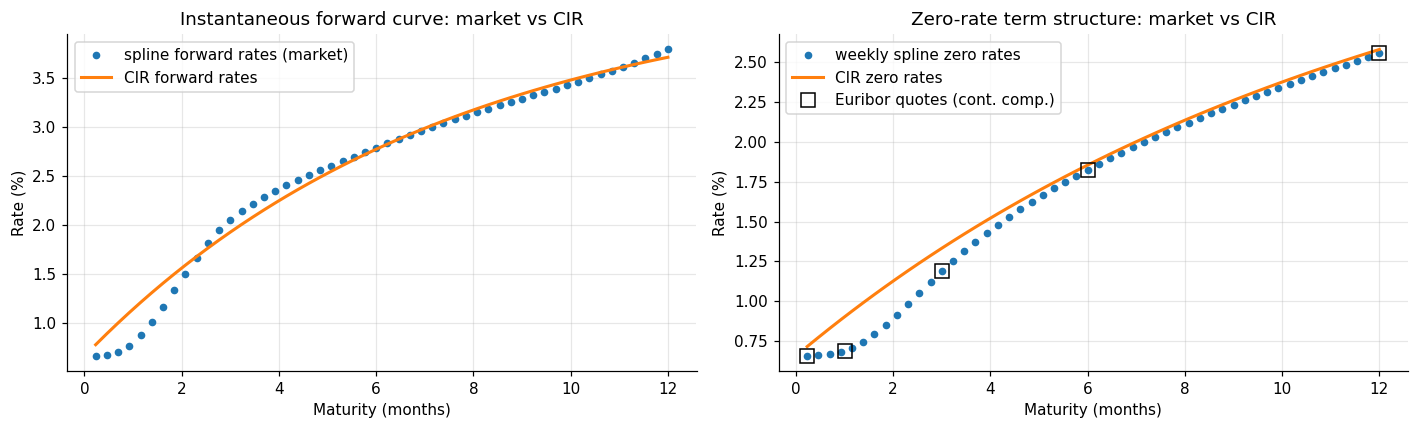

,tenor,market Euribor (%),CIR Euribor (%),error (bp)
0,1w,0.6480,0.7057,5.7744
1,1m,0.6790,0.8903,21.1252
2,3m,1.1730,1.3171,14.4100
3,6m,1.8090,1.8387,2.9678
4,12m,2.5560,2.5794,2.3389


In [ ]:
y_cir = -np.log(cir_zcb(r0_cir, t_w, *p_cir)) / t_w
L_cir_mkt = (np.exp(-np.log(cir_zcb(r0_cir, eur_T, *p_cir))) - 1) / tau   # CIR-implied Euribor at quoted tenors
fit_cir = pd.DataFrame({'tenor': ['1w', '1m', '3m', '6m', '12m'], 'market Euribor (%)': eur_L * 100,
                        'CIR Euribor (%)': L_cir_mkt * 100, 'error (bp)': (L_cir_mkt - eur_L) * 1e4})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t_w * 12, f_w * 100, 'o', ms=4, label='spline forward rates (market)')
axes[0].plot(t_w * 12, cir_forward(t_w, r0_cir, *p_cir) * 100, '-', lw=2, label='CIR forward rates')
axes[0].set_xlabel('Maturity (months)'); axes[0].set_ylabel('Rate (%)'); axes[0].set_title('Instantaneous forward curve: market vs CIR'); axes[0].legend()
axes[1].plot(t_w * 12, y_w * 100, 'o', ms=4, label='weekly spline zero rates')
axes[1].plot(t_w * 12, y_cir * 100, '-', lw=2, label='CIR zero rates')
axes[1].plot(eur_T * 12, eur_y * 100, 's', ms=9, mfc='none', mec='k', label='Euribor quotes (cont. comp.)')
axes[1].set_xlabel('Maturity (months)'); axes[1].set_ylabel('Rate (%)'); axes[1].set_title('Zero-rate term structure: market vs CIR'); axes[1].legend()
plt.tight_layout(); plt.savefig('figs/fig3a_cir_fit.png', bbox_inches='tight'); plt.show()
fit_cir

## Step 3b — Simulating the 12-month Euribor for one year [Team]
* Short rate simulated daily (250 steps over 1 year), **100,000 paths**, with the **exact** CIR transition (scaled non-central chi-square), so there is no discretisation bias and rates can never go negative.
* On each day and path, the 12-month Euribor is read off the model: $L_{12M}(t)=\big(1/B(t,t+1)-1\big)/\tau$, with $B$ the CIR bond price given $r_t$ and $\tau=365/360$. This is the rate a bank would actually fix, rather than the overnight short rate.

In [ ]:
def simulate_cir_exact(r0, kappa, theta, sigma, n_steps, n_paths, T=1.0, seed=2026):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    c = sigma ** 2 * (1 - np.exp(-kappa * dt)) / (4 * kappa)
    df_ = 4 * kappa * theta / sigma ** 2
    out = np.empty((n_steps + 1, n_paths)); out[0] = r0
    for i in range(1, n_steps + 1):
        nc = out[i - 1] * np.exp(-kappa * dt) / c
        out[i] = c * rng.noncentral_chisquare(df_, nc, n_paths)
    return out

N_SIM, N_STEPS = 100_000, 250
r_paths = simulate_cir_exact(r0_cir, k_r, th_r, s_r, N_STEPS, N_SIM)
tau12 = 365 / 360
L12 = (1 / cir_zcb(r_paths, 1.0, k_r, th_r, s_r) - 1) / tau12        # 12M Euribor on every day/path
t_grid = np.arange(N_STEPS + 1) / N_STEPS

L12_T = L12[-1]
conf = 0.95
lo, hi = np.quantile(L12_T, [(1 - conf) / 2, 1 - (1 - conf) / 2])
lo99, hi99 = np.quantile(L12_T, [0.005, 0.995])
summary_3b = pd.DataFrame({'12M Euribor (%)': [eur_L[-1] * 100, L12_T.mean() * 100, np.median(L12_T) * 100,
                                               lo * 100, hi * 100, lo99 * 100, hi99 * 100,
                                               L12_T.min() * 100, L12_T.max() * 100,
                                               L12.min() * 100, L12.max() * 100]},
    index=['today (market)', 'expected in 1y (mean)', 'median in 1y', '95% CI lower (2.5%)', '95% CI upper (97.5%)',
           '99% CI lower (0.5%)', '99% CI upper (99.5%)', 'min of 100k scenarios at 1y', 'max of 100k scenarios at 1y',
           'min over whole year, all paths', 'max over whole year, all paths'])
# analytical check: E[r_T] under CIR
print(f'E[r_1] analytic = {th_r + (r0_cir - th_r)*np.exp(-k_r):.4%}, simulated = {r_paths[-1].mean():.4%}')
summary_3b

E[r_1] analytic = 3.7606%, simulated = 3.7650%


,12M Euribor (%)
today (market),2.5560
expected in 1y (mean),4.1799
median in 1y,3.5747
95% CI lower (2.5%),2.2950
95% CI upper (97.5%),9.5023
99% CI lower (0.5%),2.2573
99% CI upper (99.5%),12.7622
min of 100k scenarios at 1y,2.2481
max of 100k scenarios at 1y,22.9369
"min over whole year, all paths",2.2481


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
months = t_grid * 12
for i in range(60):
    axes[0].plot(months, L12[:, i] * 100, lw=0.6, alpha=0.5)
q = np.quantile(L12, [0.025, 0.5, 0.975], axis=1) * 100
axes[0].fill_between(months, q[0], q[2], color='grey', alpha=0.25, label='95% band')
axes[0].plot(months, L12.mean(axis=1) * 100, 'k-', lw=2, label='expected value')
axes[0].plot(months, q[1], 'k--', lw=1, label='median')
axes[0].set_xlabel('Months ahead'); axes[0].set_ylabel('12-month Euribor (%)'); axes[0].set_title('Simulated 12-month Euribor (CIR, 100,000 paths)')
axes[0].legend(loc='upper left')
axes[1].hist(L12_T * 100, bins=150, density=True, alpha=0.75)
for x, lab, c in [(eur_L[-1] * 100, 'today', 'k'), (L12_T.mean() * 100, 'mean in 1y', 'C3'), (lo * 100, '2.5%', 'C2'), (hi * 100, '97.5%', 'C2')]:
    axes[1].axvline(x, color=c, ls='--', lw=1.2, label=f'{lab}: {x:.2f}%')
axes[1].set_xlabel('12-month Euribor in one year (%)'); axes[1].set_ylabel('Density'); axes[1].set_title('Distribution of 12-month Euribor in 1 year'); axes[1].legend()
plt.tight_layout(); plt.savefig('figs/fig3b_cir_sim.png', bbox_inches='tight'); plt.show()

### 3b(iii) — What a higher expected rate does to our product prices
The cell below reprices the two client products with the rate moved from 1.50% to the level implied by the expected 12-month Euribor in one year (continuous-compounding equivalent), keeping every other input unchanged. This isolates the pure rate effect.

In [ ]:
r_future = np.log(1 + L12_T.mean() * tau12) / 1.0
r_today12 = np.log(1 + eur_L[-1] * tau12)
cases = {'r = 1.50% (used in pricing)': r, 'r = today\'s 12M Euribor': r_today12, 'r = expected 12M Euribor in 1y': r_future}
rows = []
for name, rr in cases.items():
    c = lewis_call(S0, K_P, T_P, rr, bates_cf, p_b_lewis)
    put = c - S0 + K_P * np.exp(-rr * T_P)
    pth_ = simulate_heston_daily(p_h_lewis, S0, rr, N_A, 100_000, seed=7)
    asian = np.exp(-rr * T_A) * np.maximum(pth_.mean(axis=0) - K_A, 0).mean()
    rows.append((name, rr * 100, asian, put, np.exp(-rr)))
pd.DataFrame(rows, columns=['scenario', 'rate (%, cont.)', 'Asian call 20d', 'Put 70d 95%', '1-yr discount factor']).set_index('scenario')

,"rate (%, cont.)",Asian call 20d,Put 70d 95%,1-yr discount factor
scenario,,,,
r = 1.50% (used in pricing),1.5000,4.6764,8.8364,0.9851
r = today's 12M Euribor,2.5585,4.7307,8.4653,0.9747
r = expected 12M Euribor in 1y,4.1506,4.8128,7.9137,0.9593


---
## Summary of results

In [ ]:
summary = pd.DataFrame({
    'Heston 15d — Lewis': list(p_h_lewis) + [np.nan] * 3 + [mse_h_lewis],
    'Heston 15d — Carr-Madan': list(p_h_cm) + [np.nan] * 3 + [mse_h_cm],
    'Bates 60d — Lewis': list(p_b_lewis) + [mse_bates(p_b_lewis, d60, 'lewis')],
    'Bates 60d — Carr-Madan': list(p_b_cm) + [mse_bates(p_b_cm, d60, 'cm')]},
    index=H_NAMES + J_NAMES + ['MSE'])
print(summary.to_string(float_format=lambda x: f'{x:.4f}'))
print()
print(f'Asian call 20d ATM : fair {asian_mc:.4f}, client price {asian_client:.4f}')
print(f'Put 70d K=95%      : fair {put_fair:.4f}, client price {put_fair*(1+FEE):.4f}')
print(f'CIR                : r0 {r0_cir:.4%}, kappa {k_r:.4f}, theta {th_r:.4%}, sigma {s_r:.4f}')
print(f'12M Euribor in 1y  : mean {L12_T.mean():.4%}, 95% range {lo:.4%} – {hi:.4%} (today {eur_L[-1]:.3%})')

In [ ]:
# export the key numbers for the written report
import json
results = dict(
    heston_lewis=dict(zip(H_NAMES, map(float, p_h_lewis)), mse=float(mse_h_lewis)),
    heston_cm=dict(zip(H_NAMES, map(float, p_h_cm)), mse=float(mse_h_cm)),
    heston_nofeller=dict(zip(H_NAMES, map(float, p_nf)), mse=float(mse_heston_nofeller(p_nf, d15, 'lewis'))),
    bates_lewis=dict(zip(H_NAMES + J_NAMES, map(float, p_b_lewis)), mse=float(mse_bates(p_b_lewis, d60, 'lewis'))),
    bates_cm=dict(zip(H_NAMES + J_NAMES, map(float, p_b_cm)), mse=float(mse_bates(p_b_cm, d60, 'cm'))),
    stages_lewis=stages_lewis.to_dict(), stages_cm=stages_cm.to_dict(),
    fit_h_lewis=tab_h_lewis.to_dict('records'), fit_h_cm=tab_h_cm.to_dict('records'),
    fit_b_lewis=tab_b_lewis.to_dict('records'), fit_b_cm=tab_b_cm.to_dict('records'),
    asian=dict(mc=float(asian_mc), se=float(asian_se), euro_mc=float(euro_mc), euro_exact=float(euro_exact), client=float(asian_client)),
    conv=conv.to_dict('records'),
    put=dict(K=float(K_P), fair=float(put_fair), cm=float(put_cm), mc=float(put_mc), se=float(put_se), client=float(put_fair*(1+FEE)),
             bs=float(put_bs), iv_ref=float(iv_ref), p_itm=float((ST < K_P).mean())),
    cir=dict(r0=float(r0_cir), kappa=float(k_r), theta=float(th_r), sigma=float(s_r), mse=float(mse_cir(p_cir))),
    cir_fit=fit_cir.to_dict('records'),
    euribor=summary_3b['12M Euribor (%)'].to_dict(),
    rate_scen=rows, floor=floor.to_dict(), multistart=ms_lewis.to_dict('records'), multistart_cm=ms_cm.to_dict('records'),
    put_stage3=float(put_stage3), put_range=[float(good.put_70d_95.min()), float(good.put_70d_95.max()), int(len(good))], pcp=pcp.to_dict('records'), iv=data[['Days','Strike','Type','IV']].to_dict('records'))
with open('results.json', 'w') as fh:
    json.dump(results, fh, indent=1, default=float)
print('saved results.json')